# Motifs and deep learning

Sequence models such as chromBPNet learn to predict a genomic signal, here
chromatin accessibility, from the DNA sequence alone. What a model has
learned can be read back by asking how much each base of an input
contributed to its prediction, with attribution methods such as DeepLIFT,
and TF-MoDISco then gathers the short stretches of high contribution that
recur across thousands of regions into patterns, much as a motif discovery
tool would. This guide works through the published outputs of one such
model, from its TF-MoDISco patterns down to the contribution scores of a
single enhancer, and shows how motifs and sequences pass between the
package and a model.

The model is the chromBPNet model of ATAC-seq in the erythroleukemia cell
line K562 that ENCODE publishes as annotation
[ENCSR893SUD](https://www.encodeproject.org/annotations/ENCSR893SUD/).
Nothing here trains or runs a model, since everything we need was written
out when the model was interpreted, so no deep-learning library is needed,
though the arrays we make can be passed to PyTorch as they are. Reading
TF-MoDISco results needs the `h5py` extra and reading bigWig files the
`bigwig` extra.
The guide needs version 0.2.0 or later.

In [1]:
import json
import pathlib
import tarfile
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import universalmotif as um

pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(40);

## Downloading the data

We need two files from ENCODE, the TF-MoDISco results of the model and the
list of regions it was interpreted on, along with the JASPAR 2024
collection of vertebrate motifs. As in the other guides, a small helper
downloads each file once into a cache directory in your home folder. The
TF-MoDISco results come as a 311 MB archive holding the patterns found for
both of the model's outputs. We only use those of the counts output, which
predicts how accessible each region is, so only that file is unpacked:

In [2]:
CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"

def fetch(url, name=None):
    CACHE.mkdir(parents=True, exist_ok=True)
    path = CACHE / (name or url.rsplit("/", 1)[-1])
    if not path.exists():
        part = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, part)
        part.rename(path)
    return path

ENCODE = "https://www.encodeproject.org/files"
modisco_tar = fetch(f"{ENCODE}/ENCFF009WUL/@@download/ENCFF009WUL.tar.gz")
regions_path = fetch(f"{ENCODE}/ENCFF834JBL/@@download/ENCFF834JBL.bed.gz")
jaspar_path = fetch("https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt")

modisco_path = CACHE / "counts" / "tfmodisco.raw_output.counts.ENCSR868FGK.hd5"
if not modisco_path.exists():
    with tarfile.open(modisco_tar) as tar:
        tar.extract(f"counts/{modisco_path.name}", CACHE, filter="data")

The contribution score of every base is in a third file, a bigWig track of
2.1 GB, which we don't download at all. A bigWig file is indexed, so the
parts of the track we want can be read straight from ENCODE's server. The
genome sequence of those parts comes from the UCSC Genome Browser's API,
again without downloading the whole genome. Both count positions from 0
and leave the end out, as the package does:

In [3]:
scores_url = f"{ENCODE}/ENCFF407GCO/@@download/ENCFF407GCO.bigWig"

def hg38(chrom, start, end):
    url = f"https://api.genome.ucsc.edu/getData/sequence?genome=hg38;chrom={chrom};start={start};end={end}"
    with urllib.request.urlopen(url) as response:
        return json.load(response)["dna"].upper()

## TF-MoDISco patterns

TF-MoDISco writes its results to an HDF5 file holding, for each pattern,
the seqlets it was built from and their average contribution scores, the
pattern's contribution weight matrix or CWM.
[`read_modisco()`][universalmotif.read_modisco] reads every pattern as a
motif of type CWM, trimmed to the positions whose contribution is at least
30% of the highest:

In [4]:
cwms = um.read_modisco(modisco_path)
print(len(cwms))
cwms[0].name

60


'pos_patterns.ENCSR868FGK_ATAC_K562_ENCSR467RSV_counts_pattern_0'

The patterns come in two groups. Positive patterns are made of bases that
raised the model's prediction, and negative patterns of bases that lowered
it. Their names also carry the accessions of the experiment and the model,
which we drop, keeping the group and the number:

In [5]:
def short_name(motif):
    group, _, name = motif.name.partition(".")
    return motif.replace(name=f"{group[:3]}_{name.rsplit('_', 1)[1]}")

cwms = [short_name(m) for m in cwms]
pos = [m for m in cwms if m.name.startswith("pos")]
neg = [m for m in cwms if m.name.startswith("neg")]
print(len(pos), len(neg))
pl.DataFrame({
    "pattern": [m.name for m in cwms],
    "seqlets": [int(m.nsites) for m in cwms],
    "width": [m.width for m in cwms],
    "consensus": [m.consensus for m in cwms],
}).head(8)

44 16


pattern,seqlets,width,consensus
str,i64,i64,str
"""pos_0""",36546,5,"""GATAA"""
"""pos_1""",33538,14,"""CCACYAGGGGGCGS"""
"""pos_2""",27345,9,"""GCCCCGCCC"""
"""pos_3""",13390,10,"""GCTGAGTCAY"""
"""pos_4""",9410,7,"""CTTCCGG"""
"""pos_5""",6024,7,"""YGATTGG"""
"""pos_6""",4957,11,"""GCGCATGCGCR"""
"""pos_7""",4175,8,"""TTGCATCA"""


Within each group the patterns are ordered by their number of seqlets, so
the most common pattern the model relies on is the short `GATAA`, found
over 36,000 times. A CWM gives the average contribution of each letter at
each position, so its logo shows how much each base mattered to the model
rather than how often it was seen, and the letters of negative patterns
hang below zero. Here are the first five positive patterns and the first
two negative ones, drawn as they are rather than aligned to one another:

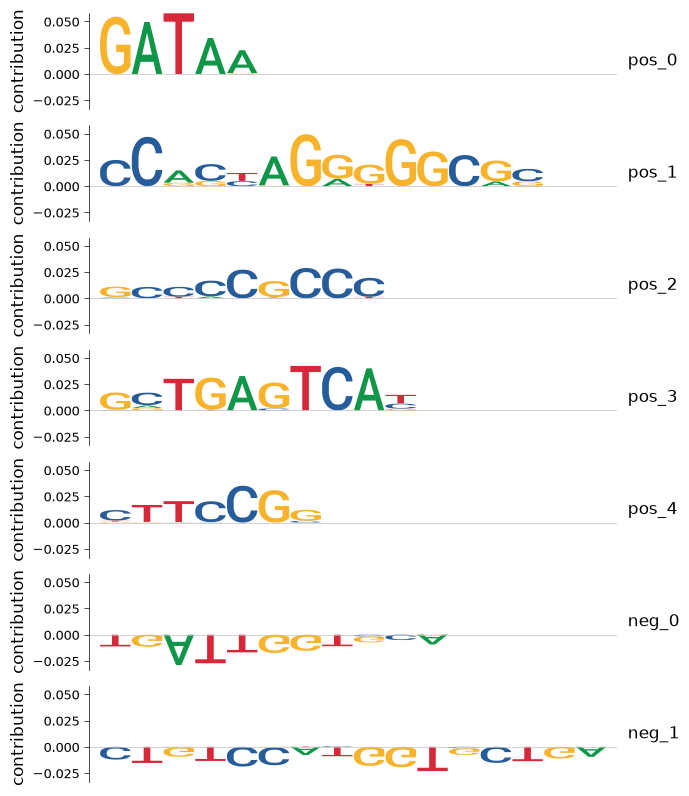

In [6]:
fig = um.view_motifs(pos[:5] + neg[:2], use_type="CWM", rc=False, align=False,
                     names_pos="right", show_positions=False, figsize=(7, 8))

All seven are drawn on the same scale, which shows how much weaker the
negative patterns are than the strongest positive ones.

## Naming the patterns

TF-MoDISco finds patterns without knowing which proteins bind them, so the
next step is to match them to known motifs. Comparisons work on
probabilities, and with `type="PPM"`, `read_modisco()` gives each pattern as
the letter frequencies of its seqlets instead. We also trim less here,
keeping positions with at least 20% of the highest contribution, for a
reason the first pattern shows:

In [7]:
ppms = [short_name(m) for m in um.read_modisco(modisco_path, type="PPM", trim_threshold=0.2)]
print(pos[0].consensus, ppms[0].consensus)

GATAA KNNNNNNNNWGATAAG


At the default cutoff the first pattern is just the five letters `GATAA`,
which is too short to stand out against a database of nearly 900 motifs,
whereas the wider version keeps enough of its flanks to be matched with
confidence. We compare every pattern to JASPAR with
[`compare_motifs()`][universalmotif.compare_motifs], as in the
[ChIP-seq workflow](chipseq-workflow.ipynb), and keep the best match of
each:

In [8]:
jaspar = um.read_meme(jaspar_path)
tf_names = {m.name: m.altname for m in jaspar}
cmp = um.compare_motifs(ppms + jaspar, compare_to=list(range(len(ppms))), qvalue=0.05, nthreads=2)
best = (
    cmp.filter(pl.col("target_i") >= len(ppms))
    .with_columns(tf=pl.col("target").replace_strict(tf_names))
    .sort("qvalue")
    .group_by("subject", maintain_order=True)
    .first()
)
summary = pl.DataFrame({
    "pattern": [m.name for m in ppms],
    "seqlets": [int(m.nsites) for m in ppms],
    "consensus": [m.consensus for m in ppms],
}).join(best.select(pattern="subject", tf="tf", qvalue="qvalue"), on="pattern", how="left")
summary.head(20)

pattern,seqlets,consensus,tf,qvalue
str,i64,str,str,f64
"""pos_0""",36546,"""KNNNNNNNNWGATAAG""","""GATA2""",0.002153
"""pos_1""",33538,"""CCASYAGRKGGCRSY""","""CTCF""",3.4323e-16
"""pos_2""",27345,"""NGCCCCGCCCCC""","""KLF12""",5.5433e-7
"""pos_3""",13390,"""GMTGAGTCAY""","""Bach1::Mafk""",0.000021
"""pos_4""",9410,"""NRCTTCCGG""","""ELK4""",3.6105e-7
"""pos_5""",6024,"""NNNYNCYSATTGGCYN""","""NFYA""",0.00908
"""pos_6""",4957,"""NGCGCNTGCGCN""","""Nrf1""",0.000018
"""pos_7""",4175,"""RTTGCATCAK""","""ATF4""",0.000005
"""pos_8""",3682,"""NCACTTCCTSTTT""","""SPIB""",0.00002


Most of the common patterns match the motifs of factors known to be active
in K562 cells. The GATA motif of `pos_0` is bound there by GATA1, a master
regulator of red blood cell development, and `pos_3` and `pos_9` are the
MAF recognition element bound by NF-E2, another erythroid factor, which
shares it with BACH1 and the small MAF proteins, hence the best match of
`pos_3`. Alongside
them are factors found at regulatory elements in most cell types, such as
CTCF, the GC box of the SP and KLF families, ETS factors, NF-Y, NRF1, and
the AP-1 and ATF families. Note that the best match is only the closest
motif in JASPAR, and the factors of a family often share one motif, so
`KLF12` here stands for the SP and KLF families as a whole rather than
KLF12 itself. The negative patterns are next:

In [9]:
summary.filter(pl.col("pattern").str.starts_with("neg"))

pattern,seqlets,consensus,tf,qvalue
str,i64,str,str,f64
"""neg_0""",503,"""CTGATTGGTSCRT""","""NFYC""",0.021664
"""neg_1""",235,"""CTGTCCRTGGTGCTGAA""","""REST""",1.7288e-10
"""neg_2""",203,"""NNDNNNDNNWTGATKGATGSATNNATNN""","""PBX1""",0.03364
"""neg_3""",184,"""VDGNTGGCATCNN""",null,null
"""neg_4""",156,"""GYRTGGTGGYGBRCACCTGTART""","""SNAI2""",0.001855
"""neg_5""",148,"""NAGRTGGGCAYCN""",null,null
"""neg_6""",131,"""NNNNATCCATGATGVTNNNNNNN""",null,null
"""neg_7""",115,"""NNNNNNATGATGATSATGATGATGATGATG""",null,null
"""neg_8""",103,"""GATGAGATTTGGGTGGGGACA""","""KLF4""",0.005996


The negative patterns are much rarer, the most common seen in 503
seqlets, and fewer of them match a known motif. The clearest is `neg_1`,
the motif of REST, a repressor that silences neuronal genes outside the
nervous system, so the model has learned that REST sites make a region
less accessible in these cells. Others are harder to read: `neg_0` and
`neg_10` resemble the NF-Y motif, which is also among the positive
patterns, and some, such as the `ATGATG` repeats of `neg_7`, match nothing
at all.

[`plot_modisco()`][universalmotif.plot_modisco] draws the same summary in
the style of TF-MoDISco's own reports, with a row for each pattern that
holds its number of seqlets, its CWM, its letter frequencies and its best
match, turned to read the same way as the pattern. It reads the patterns
from the results file and finds their matches in the comparison by either
their full names or short labels such as `pos_0`. Here are the eight most
common positive patterns and three of the negative ones:

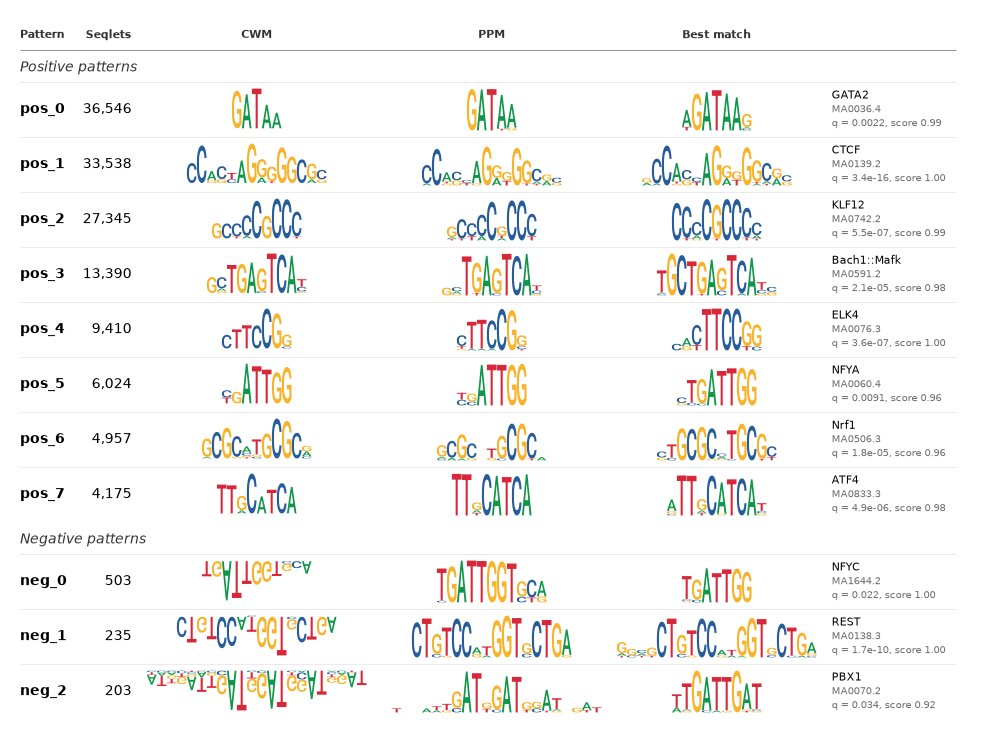

In [10]:
fig = um.plot_modisco(modisco_path, matches=cmp, database=jaspar, patterns=(8, 3))

The CWMs of the negative patterns point down, since their bases lowered
the prediction, while their letter frequencies read like those of any
other motif.

## Contribution scores along the genome

The patterns summarize what the model learned across all regions, while
the contribution scores show it at work in each one. The regions file
lists the 1 kb windows the scores were computed for:

In [11]:
regions = pl.read_csv(regions_path, separator="\t", has_header=False,
                      new_columns=["chrom", "start", "end"])
print(regions.height)
regions.head(3)

269718


chrom,start,end
str,i64,i64
"""chr1""",100028707,100029707
"""chr1""",100027505,100028505
"""chr1""",100028104,100029104


We look at hypersensitive site 2 of the β-globin locus control region, a
well-studied erythroid enhancer that drives the expression of the globin
genes in K562 cells, and pick the window that covers its core, keeping its
row number in the file for later:

In [12]:
hs2 = regions.with_row_index().filter(
    pl.col("chrom") == "chr11", pl.col("start") <= 5_280_600, pl.col("end") >= 5_280_900,
)
hs2

index,chrom,start,end
u32,str,i64,i64
50341,"""chr11""",5280325,5281325


[`signal_values()`][universalmotif.signal_values] reads the score of every
base of the window from the remote track, and `hg38()` fetches its
sequence. The track holds one score per base, that of the base in the
genome, so [`view_attributions()`][universalmotif.view_attributions] draws
the sequence itself with each letter scaled by its contribution, with
positions along the chromosome:

1000 -0.0186 0.144


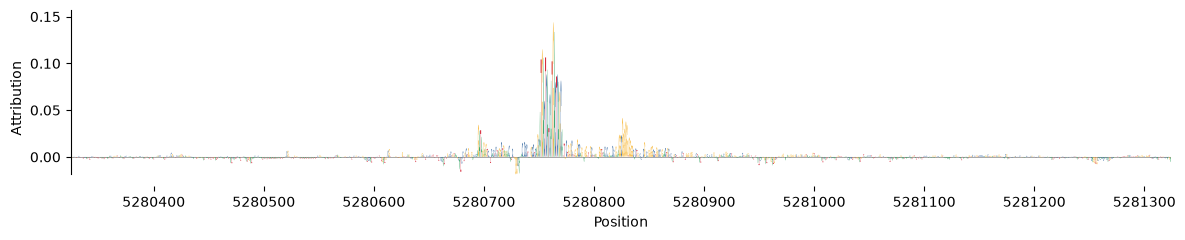

In [13]:
row, chrom, start, end = hs2.row(0)
scores = um.signal_values(scores_url, chrom, start, end)
seq = hg38(chrom, start, end)
print(len(seq), scores.min().round(4), scores.max().round(4))
ax = um.view_attributions(scores, seq, start=start, figsize=(12, 2.5))

Most of the window contributes little or nothing, apart from a stretch of
about 150 bases in the middle that holds the core of HS2, and a few bases
score below zero, meaning that the model expects the region to be a little
less accessible because of them. To see which patterns the peaks belong
to, we scan the window with the positive patterns that matched a known
motif and label each hit with its match. A strict P-value cutoff, and
removing overlapping hits across strands and patterns, keeps only the
clearest sites:

In [14]:
named = {m.name: m for m in ppms}
labels = dict(best.select("subject", "tf").iter_rows())
hits = um.scan_sequences(
    [named[p] for p in labels if p.startswith("pos")], seq, pvalue=1e-5,
    no_overlaps=True, no_overlaps_by_strand=True, no_overlaps_by_motif=True,
)
hits = hits.with_columns(motif=pl.col("motif").replace_strict(labels)).sort("start")
hits.select("motif", "start", "end", "strand", "match", "pvalue")

motif,start,end,strand,match,pvalue
str,i64,i64,str,str,f64
"""Bach1::Mafk""",426,436,"""-""","""GATGAGTCAT""",0.000003
"""Bach1::Mafk""",436,446,"""-""","""GCTGAGTCAT""",9.5367e-7
"""KLF12""",501,513,"""-""","""TGCCCCACCCCC""",0.000005


The hits are counted along the sequence from 0, as `view_attributions()`
expects, while `region` is given in positions along the chromosome, the
same as the axis:

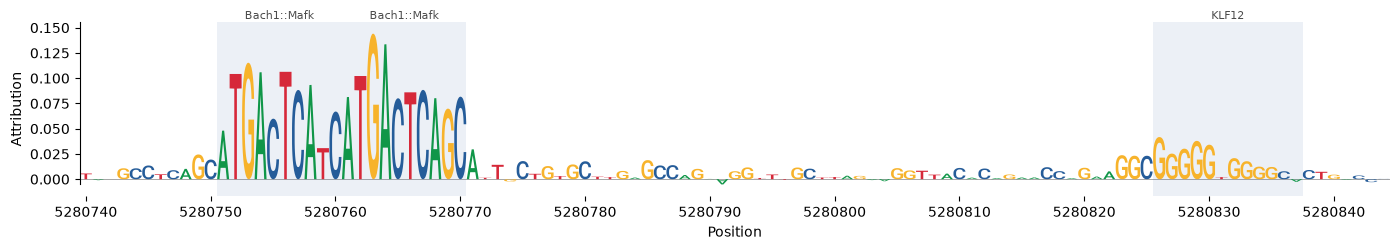

In [15]:
ax = um.view_attributions(scores, seq, start=start, region=(start + 415, start + 520), hits=hits)

The tallest peak is a pair of NF-E2 sites in tandem, `GATGAGTCAT` and
`GCTGAGTCAT` on the reverse strand, labelled with the BACH1::MAFK motif
that their pattern matches best. Together they make up most of the
window's total score:

In [16]:
round(float(scores[426:446].sum() / scores.sum()), 2)

0.66

The tandem NF-E2 sites are the best-known feature of HS2 and are needed for
its activity as an enhancer, and the model has found them from
accessibility alone. The smaller peak to the right is a GC-rich SP or KLF
site, and the one at 5,280,695 in the full window sits on `AGATAG`, a GATA
site too weak to pass the scan's cutoff.

The same ENCODE models come with the ATAC signal itself, as Tn5 insertions
at each base, and the profile they predict from the sequence alone, both as
bigWig tracks. With `kind="signal"`,
[`view_attribution_tracks()`][universalmotif.view_attribution_tracks] draws
such tracks as plain values above the contribution scores, with the hits
marked through all of them:

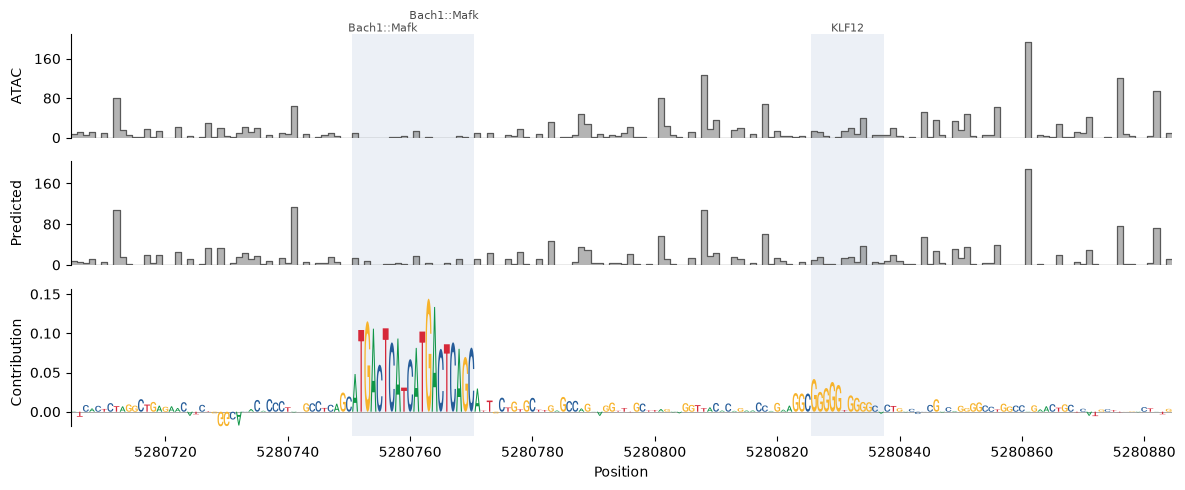

In [17]:
encode_files = {"ATAC": "ENCFF874FUM", "Predicted": "ENCFF172RSF"}
tracks = {
    name: um.signal_values(f"{ENCODE}/{acc}/@@download/{acc}.bigWig", chrom, start, end)
    for name, acc in encode_files.items()
}
tracks["Contribution"] = scores
fig = um.view_attribution_tracks(
    tracks, seq, kind={"ATAC": "signal", "Predicted": "signal"}, start=start,
    region=(start + 380, start + 560), hits=hits, figsize=(12, 5),
)

Insertions vary a great deal from one base to the next, and the model
predicts that pattern closely. Almost none fall within the tandem NF-E2
sites, whose bases contribute the most, while there are plenty on either
side, likely the footprint of a protein protecting its site from Tn5, which
the model has learned to expect there too.

## Hypothetical contribution scores

The track only holds the score of the base in the genome at each position.
Attribution methods also give hypothetical scores, the contribution each of
the four letters would make at each position, which show what the model
would accept at a site and not only what is there. TF-MoDISco keeps these
for every seqlet, along with the row of the regions file the seqlet came
from and where it lies in the central 500 bases of that window.
[`read_seqlets()`][universalmotif.read_seqlets] reads the seqlets of every
pattern as a table like that of a scan, and given the regions and the
width of the central window, it places them on the genome. With `scores`,
each seqlet also carries its scores, turned to run along the genome for
seqlets found on the reverse strand. We shorten the pattern names as
before, and keep the seqlets that fall in the HS2 window:

In [18]:
seqlets = um.read_seqlets(modisco_path, regions=regions, window=500, scores="hypothetical")
seqlets = seqlets.with_columns(pl.col("motif").str.replace(r"^(pos|neg)_patterns\..*_(\d+)$", "${1}_${2}"))
found = seqlets.filter(pl.col("sequence_i") == row)
found.select("motif", "start", "end", "strand", "match")

motif,start,end,strand,match
str,i64,i64,str,str
"""pos_0""",5280678,5280708,"""+""","""ATCCTGCTGGGGACCCAGATAGGAGTCATC"""
"""pos_3""",5280751,5280781,"""-""","""GCACAGCAATGCTGAGTCATGATGAGTCAT"""


Two seqlets were found in the window. One belongs to the NF-E2 pattern and
covers the tandem sites, and the other belongs to the GATA pattern and
covers the `AGATAG` site that our scan missed, so TF-MoDISco counted it
after all. As a check, the hypothetical scores of the bases in the genome
should be the scores in the bigWig track:

In [19]:
nfe2 = found.filter(pl.col("motif") == "pos_3").row(0, named=True)
nfe2_scores = np.asarray(nfe2["scores"])
a, b = nfe2["start"] - start, nfe2["end"] - start
observed = (um.one_hot(seq[a:b])[0] * nfe2_scores).sum(axis=0)
np.allclose(observed, scores[a:b], atol=1e-3)

True

[`view_attribution_tracks()`][universalmotif.view_attribution_tracks] draws
several tracks of the same stretch of sequence one above the other. Here
the scores from the bigWig track sit above the hypothetical scores of the
seqlet, drawn twice: with `kind="all"`, which draws every letter at every
position, those that would raise the prediction above zero and those that
would lower it below, and with `kind="heatmap"`, which shows the same
scores as colours, with dots marking the sequence:

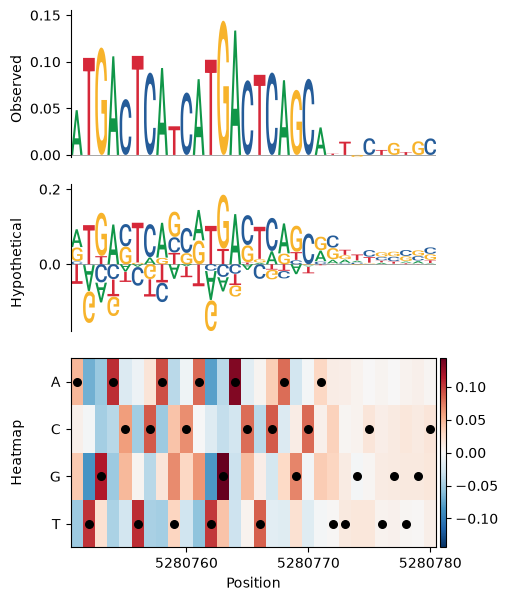

In [20]:
fig = um.view_attribution_tracks(
    {"Observed": scores[a:b], "Hypothetical": nfe2_scores, "Heatmap": nfe2_scores},
    seq[a:b], kind={"Hypothetical": "all", "Heatmap": "heatmap"}, start=nfe2["start"],
)

Across the two sites, the letter in the genome is nearly always the one the
model scores highest, and most of the other letters score below zero, so
the model expects almost any change to the sites to make the enhancer less
accessible. The scores fade quickly past the second site, from about
5,280,772 on, where no letter matters much.

Without the model itself we cannot predict what changing a letter would do,
but we can ask how each change would alter the motifs in the window.
[`variant_motif_effects()`][universalmotif.variant_motif_effects] scores
every possible substitution, or a table of variants, against the motifs,
keeping the changes to sites that pass the cutoff before or after, and
[`plot_variant_effects()`][universalmotif.plot_variant_effects] draws the
largest change at each position along the sequence, with the hits beneath:

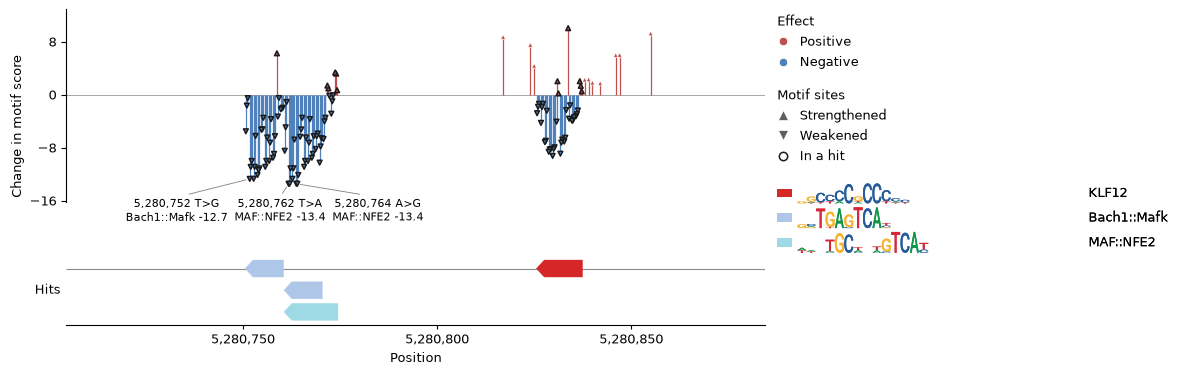

In [21]:
motifs = [named[p].replace(name=labels[p]) for p in labels if p.startswith("pos")]
a, b = 380, 560
changes = um.variant_motif_effects(None, seq[a:b], motifs, start=start + a, pvalue=1e-5)
strongest = changes.sort(pl.col("delta").abs(), descending=True).unique(
    "variant", keep="first", maintain_order=True
)
fig = um.plot_variant_effects(
    strongest.select("position", "ref", "alt", pl.col("delta").alias("effect")),
    sequence=seq[a:b], motifs=motifs, start=start + a, pvalue=1e-5,
    ylabel="Change in motif score", labels=3,
)

Nearly every substitution within the NF-E2 sites weakens them, by up to 13
units of score, whereas a few changes to the right would strengthen or
create GC-rich sites. With a model, the same plot takes its predicted effect
of each variant instead, such as those from
[`mutagenesis_effects()`][universalmotif.mutagenesis_effects].

The NF-E2 pattern is the average of 13,390 seqlets like this one.
[`plot_seqlets()`][universalmotif.plot_seqlets] draws them one row each,
with the contribution of each position as a colour on the left and the
letters on the right, sorted from the strongest seqlet down and each read
along the pattern. Patterns can be named here by their short labels:

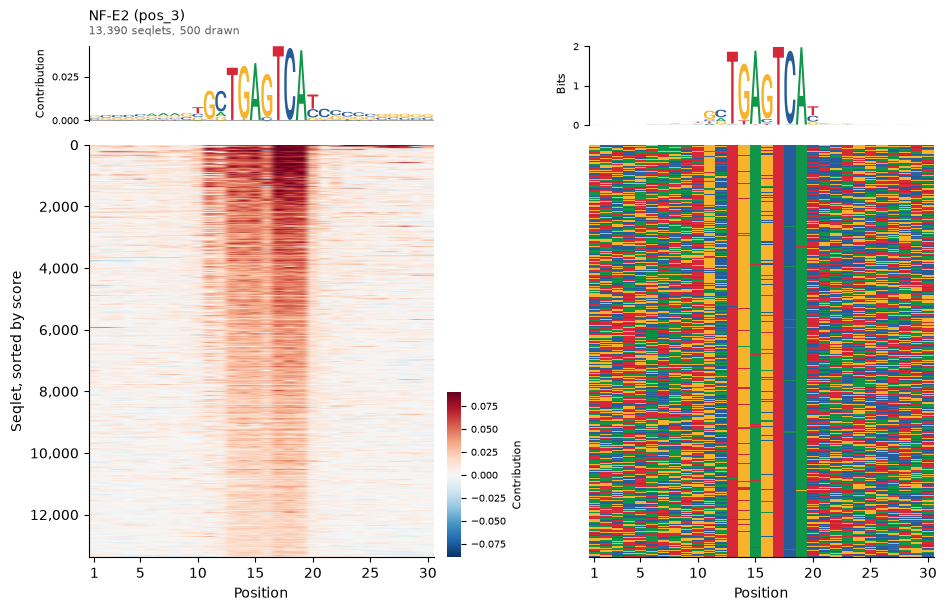

In [22]:
fig = um.plot_seqlets(seqlets, "pos_3", title="NF-E2 (pos_3)")

The core `TGAGTCA` is the same in nearly every seqlet, while the letters
around it vary freely, and its contribution fades steadily from the
strongest seqlets to the weakest without changing shape, so the pattern is
not an average of distinct kinds of sites.

## Motifs as convolution filters

The first layer of most sequence models is a convolution, which slides a
set of filters along the sequence much as a scan slides a position weight
matrix. [`one_hot()`][universalmotif.one_hot] gives sequences as arrays of
shape (sequences, letters, length), the layout PyTorch's `Conv1d` takes,
and [`to_filters()`][universalmotif.to_filters] gives motifs as weights of
shape (filters, letters, width). The pattern's PPM has letters that no
seqlet had, whose log-odds would be infinite, so
[`normalize()`][universalmotif.normalize] adds a pseudocount first, and
with `rc` the reverse complement of the motif follows it as a second
filter:

In [23]:
mare = um.normalize(named["pos_3"])
filters = um.to_filters(mare, rc=True)
x = um.one_hot(seq)
print(x.shape, filters.shape)

(1, 4, 1000) (2, 4, 10)


A convolution without a bias sums the product of the filter and the
sequence over every window, which numpy can do directly:

In [24]:
windows = np.lib.stride_tricks.sliding_window_view(x, filters.shape[2], axis=-1)
conv = np.einsum("fcw,ncpw->nfp", filters, windows)[0]
print(conv.argmax(axis=1), conv.max(axis=1).round(3))
um.scan_sequences(mare, seq, pvalue=1e-4).select("start", "end", "strand", "score", "pvalue")

[425 436] [10.501 16.835]


start,end,strand,score,pvalue
i64,i64,str,f64,f64
425,435,"""+""",10.498,0.000074
426,436,"""-""",15.941,0.000003
436,446,"""-""",16.83,9.5367e-7


The best window of the forward filter starts at 425 and that of the
reverse filter at 436, the same sites that
[`scan_sequences()`][universalmotif.scan_sequences] finds, with the same
scores to within a few thousandths, since scanning rounds the matrix to
compute exact P-values. The same filters can be given to a model, for
example to start its first layer from known motifs:

```python
import torch

conv = torch.nn.Conv1d(4, filters.shape[0], filters.shape[2], bias=False)
with torch.no_grad():
    conv.weight.copy_(torch.from_numpy(filters))
```

Going the other way, [`from_filters()`][universalmotif.from_filters] turns
filters into motifs, so the first-layer weights of a trained model can be
compared with known motifs or drawn like any other. Here we turn our two
filters back into motifs:

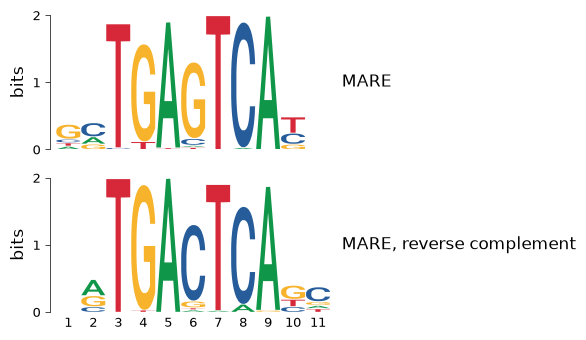

In [25]:
back = um.from_filters(filters, names=["MARE", "MARE, reverse complement"])
fig = um.view_motifs(back, rc=False, names_pos="right", figsize=(6, 3.5))

## Experiments on a model

Contribution scores explain the predictions a model makes for the
sequences it was given, and the other common way to question a model is to
change its input and watch the prediction. We don't have the model itself
here, so the code in this section is not run, and `model` stands for a
function that takes a list of sequences and returns one prediction for
each, such as the predicted total counts of chromBPNet.

To measure the effect of a motif on its own,
[`insert_sites()`][universalmotif.insert_sites] writes the same site into
the middle of every background sequence, and the predictions before and
after are compared with
[`plot_marginalization()`][universalmotif.plot_marginalization], which
draws their distributions side by side along with the mean change. Several
insertions can be compared at once, for example the NF-E2 site against
half of it or a version with a single mutation:

```python
bkg = um.shuffle_sequences(peak_seqs, k=2, seed=1)  # shuffles of some peaks
before = model(bkg)
fig = um.plot_marginalization(before, {
    "NF-E2": model(um.insert_sites(bkg, "TGCTGAGTCAT")),
    "half site": model(um.insert_sites(bkg, "TGAGTCA")),
    "mutated": model(um.insert_sites(bkg, "TGCTGAGTAAT")),
})
```

Pairs of factors that bind together often do so best at particular
distances, such as a whole number of turns of the helix apart.
[`site_spacings()`][universalmotif.site_spacings] writes two sites into the
background at a range of spacings, and
[`plot_spacing()`][universalmotif.plot_spacing] draws the mean change in
prediction at each spacing, with `helix=True` marking every 10.5 bases from
the strongest:

```python
pairs = um.site_spacings(bkg, "AGATAAG", "TGCTGAGTCAT", spacings=range(41))
fig = um.plot_spacing({d: model(seqs) for d, seqs in pairs.items()},
                      baseline=before, helix=True)
```

The effect of every single-letter change to one sequence comes from
[`mutagenesis()`][universalmotif.mutagenesis] and
[`mutagenesis_effects()`][universalmotif.mutagenesis_effects], and can be
drawn with `view_attributions(..., kind="heatmap")` like the hypothetical
scores above.

## Reading contribution score files

Here the scores came from a bigWig track and from TF-MoDISco's seqlets, but
the full hypothetical scores of every region are usually kept in files of
their own. chromBPNet writes them, along with the one-hot sequences, to
HDF5 files named `<prefix>.counts_scores.h5` and
`<prefix>.profile_scores.h5`, next to a file of the regions they cover,
and for a full set of peaks these are often tens of gigabytes.
[`read_contributions()`][universalmotif.read_contributions] reads them,
optionally just some of the sequences, and gives each sequence its genomic
window, so that its `view()` method labels positions along the chromosome:

```python
contribs = um.read_contributions("model.counts_scores.h5", indices=range(100))
contribs.names[:3]
contribs.view(0, kind="heatmap")
```

The scores and one-hot sequences that TF-MoDISco itself takes, as numpy
files, are read the same way:

```python
contribs = um.read_contributions("shap.npz", sequences="ohe.npz")
```

From there, the scores of each sequence are a numpy array, and the
sequences are strings that can be scanned, compared or summarized with the
rest of the package.